Has a fairly complex source description. 

In [1]:
%run -i clean_script.py
import openmc
import numpy as np

model = openmc.model.Model()

# Material definitions
materials=openmc.Materials()

m1 = openmc.Material(name='m1')
m1.add_element('C',0.4)
m1.add_element('O',0.2)
m1.add_nuclide('Na23',0.2)
m1.add_element('Cu',0.2)
m1.set_density('g/cc',0.9)
materials.append(m1)

m2 = openmc.Material(name='m2')
m2.add_nuclide('U238',0.98)
m2.add_nuclide('U235',0.02)
m2.set_density('g/cc',18)
materials.append(m2)

m3 = openmc.Material(name='m3')
m3.add_nuclide('H1',1)
m3.set_density('g/cc',1)
materials.append(m3)

model.materials = materials

In [2]:
# Surface definitions
s1 = openmc.XPlane(50)
s2 = openmc.XPlane(0)
s3 = openmc.XPlane(-50)
s4 = openmc.YPlane(-20)
s5 = openmc.YPlane(20)
s6 = openmc.ZPlane(60)
s7 = openmc.ZPlane(-60)

s11 = openmc.XPlane(8.334)
s12 = openmc.XPlane(-8.334)
s13 = openmc.YPlane(-6.67)
s14 = openmc.YPlane(6.67)
s15 = openmc.XPlane(25)

s17 = openmc.YPlane(0)
s18 = openmc.YPlane(10)
s19 = openmc.ZCylinder(r=3,x0=10,y0=5)
s20 = openmc.ZCylinder(r=3,x0=10,y0=5) # why a duplicate surface?
s21 = openmc.XPlane(4)
s22 = openmc.XPlane(-4)
s23 = openmc.YPlane(-3)
s24 = openmc.YPlane(3)

s31 = openmc.XPlane(20)
s32 = openmc.XPlane(16)
s33 = openmc.YPlane(3)
s34 = openmc.YPlane(6)

In [3]:
w = (100, 100)

(16.668, 13.34)
BoundingBox(lower_left=(-50.0, -20.0, -60.0), upper_right=(0.0, 20.0, 60.0))


<Axes: xlabel='x [cm]', ylabel='y [cm]'>

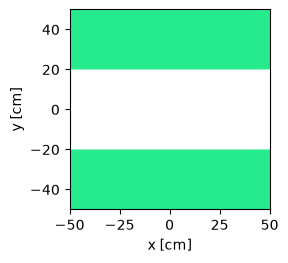

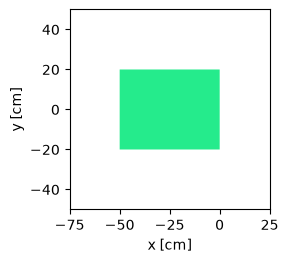

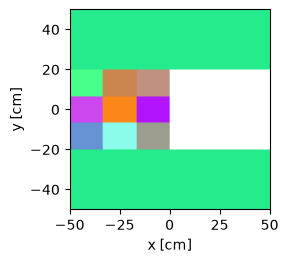

In [4]:
# Universe definitions
c1 = openmc.Cell(fill=None,region=(+s1|-s3|-s4|+s5|+s6|-s7))
c1.plot(width=w)

c2_region = (-s2&+s3&+s4&-s5&-s6&+s7)
             
# to be filled with u1
c2 = openmc.Cell(fill=None,region=c2_region)
c2.plot(width=w)

def u1():
    c4 = openmc.Cell(fill=None,region=(-s11&+s12&-s14&+s13))
    return openmc.Universe(cells=[c4])

c2_fill = openmc.RectLattice()
c2_fill.pitch = (16.668,13.34)#(8.334*2, 6.67*2)
print(c2_fill.pitch)
c2_fill.lower_left = (-50, -20)  # by inspection
c2_fill.universes=[[u1(), u1(), u1()],
                   [u1(), u1(), u1()],
                   [u1(), u1(), u1()],]
#c2_fill.outer=openmc.Universe(cells=[c1])
print(c2.bounding_box)
c2.fill=c2_fill
geometry = openmc.Geometry([c1,c2])
geometry.plot(width=w)

As with the last example, the bounding box of the universe containing c5 is not symmetric with respect to the universe's origin. We will need to translate it by `(-12.5, -5, 0)` which will allow `openmc.RectLattice` towork correctly. This is what it looks like without performing the translation:
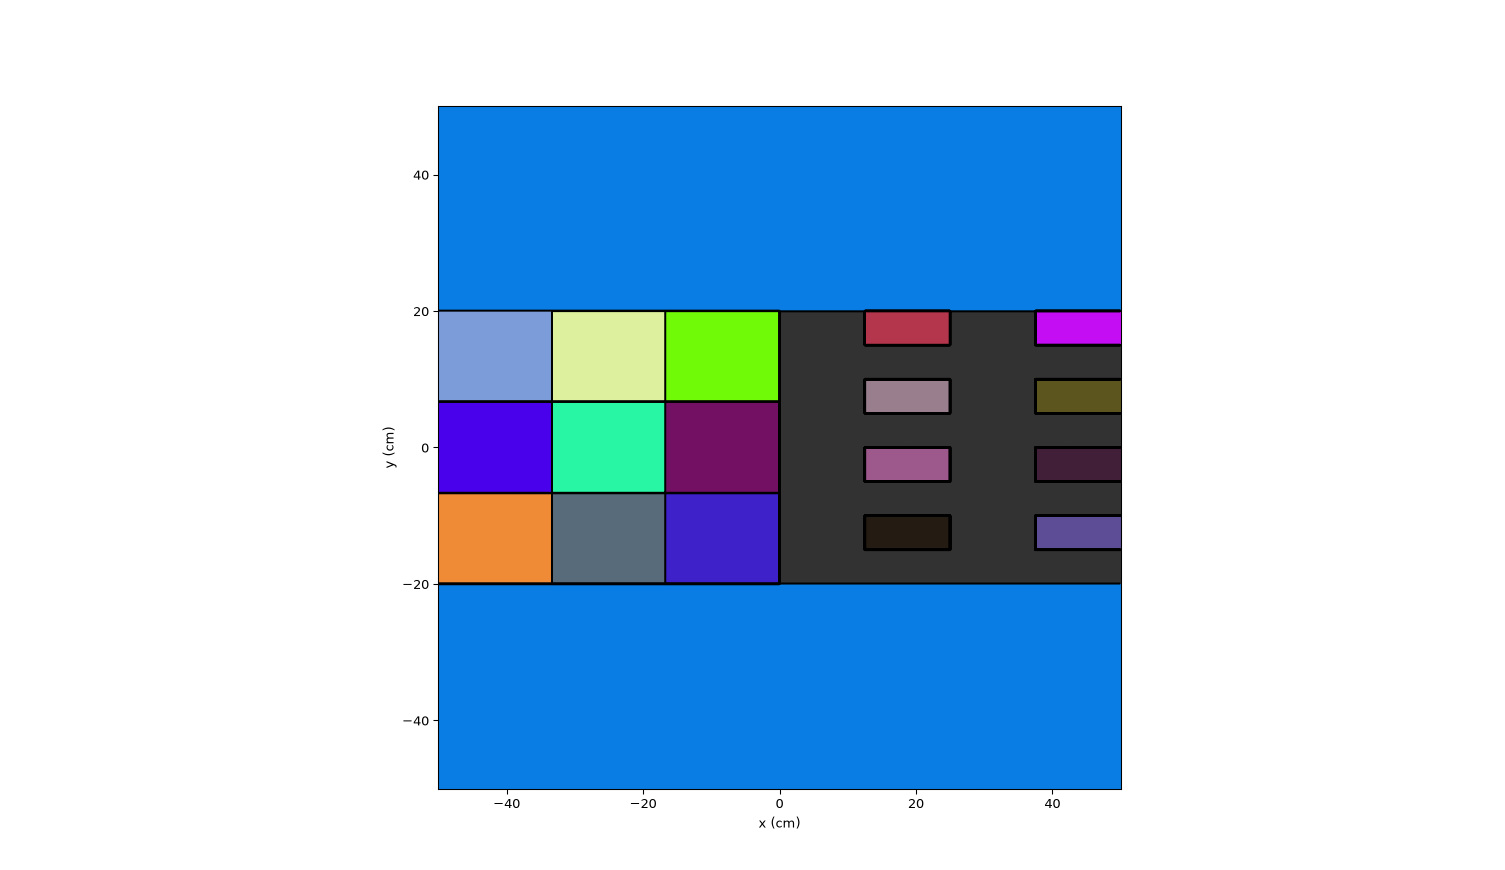

<Axes: xlabel='x [cm]', ylabel='y [cm]'>

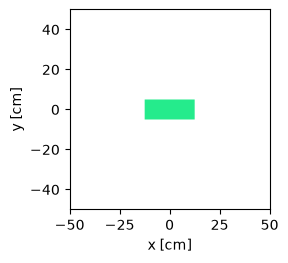

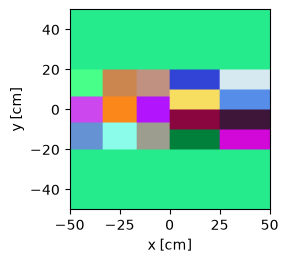

In [5]:
def u2():
    c5_region=-s15&+s2&-s18&+s17
    c5_region=c5_region.translate((-12.5,-5,0))
    c5 = openmc.Cell(fill=m3,region=c5_region)
    
    return openmc.Universe(cells=[c5])

c3_region=(-s1&+s2&+s4&-s5&-s6&+s7)
c3 = openmc.Cell(fill=None,region=c3_region)
c3_fill = openmc.RectLattice()
c3_fill.lower_left=(0,-20)
c3_fill.pitch=(25,10)
c3_fill.universes=[[u2(),u2()],
              [u2(),u2()],
              [u2(),u2()],
              [u2(),u2()],]
c3.fill=c3_fill

geometry = openmc.Geometry(u2())
geometry.plot(width=w)

geometry = openmc.Geometry([c1,c2,c3])
geometry.plot(width=w)

Now, for universe 3, which fills cell c4 of universe 1:

<Axes: xlabel='x [cm]', ylabel='y [cm]'>

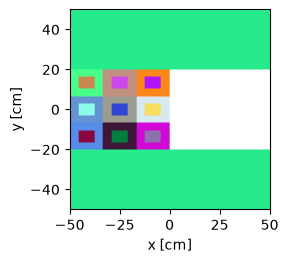

In [6]:
def u3():
    c6 = openmc.Cell(fill=m1,region=+s21|-s22|-s23|+s24)
    c8 = openmc.Cell(fill=m2,region=+s19)
    return openmc.Universe(cells=[c6,c8])

def u1():
    c4 = openmc.Cell(fill=u3(),region=(-s11&+s12&-s14&+s13))
    return openmc.Universe(cells=[c4])

c2_fill = openmc.RectLattice()
c2_fill.pitch = (16.668,13.34)
c2_fill.lower_left = (-50, -20)
c2_fill.universes=[[u1(), u1(), u1()],
                   [u1(), u1(), u1()],
                   [u1(), u1(), u1()],]
c2.fill=c2_fill
geometry = openmc.Geometry([c1,c2])
geometry.plot(width=w)

Filling universe 2 is more complicated since the MCNP input defines both a material fill for each instance of Cell 5 in its lattice, as well as Universe Fill for it (u4) (and even a TR for a certain instance). In OpenMC, a cell can either be filled with a material, or a universe (or lattice), but not both simultaneously. 

<Axes: xlabel='x [cm]', ylabel='y [cm]'>

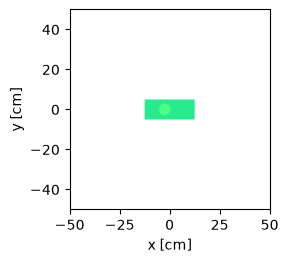

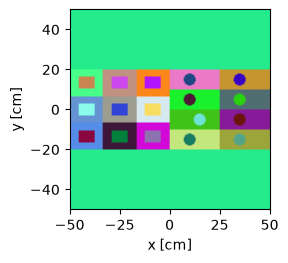

In [7]:
def u4():
    c7_region = +s19
    c11_region = -s18&-s19

    # Because c5_region is translated by (-12.5, -5, 0), the same must be done for these regions.
    c7_region = c7_region.translate((-12.5,-5,0))
    c11_region = c11_region.translate((-12.5,-5,0))
    c7 = openmc.Cell(fill=m1,region=c7_region)
    c11 = openmc.Cell(fill=m2,region=c11_region)
    return openmc.Universe(cells=[c7,c11])

# replace material fill of c5 since it will be overwritten by c7
def u2(u4_tr=None):
    c5_region=-s15&+s2&-s18&+s17
    c5_region=c5_region.translate((-12.5,-5,0))
    c5 = openmc.Cell(fill=u4(),region=c5_region) 
    if u4_tr:
        c5.translation = u4_tr
    return openmc.Universe(cells=[c5])

c3_fill.universes=[[u2(),u2()],
                  [u2(),u2()],
                  [u2((5,0,0)),u2()],
                  [u2(),u2()],]
c3.fill=c3_fill

geometry = openmc.Geometry(u2())
geometry.plot(width=w)

geometry = openmc.Geometry([c1,c2,c3])
geometry.plot(width=w)

The MCNP input describes the source
"In this example, a distributed volumetric source located in each of the ten boxes and eight circles (in two dimensions) is desired. 

WIP

In [8]:
# Universe 5 is defined in the MCNP input but does not appear to be used. 
def u5():
    c9 = openmc.Cell(fill=m1,region=+s20&(+s31|-s32|-s33|+s34))
    c13 = openmc.Cell(fill=m2,region=-s18&-s20)
    c15 = openmc.Cell(fill=m2,region=-s18&-s31&+s32&+s33&-s34)
    return openmc.Universe(cells=[c9,c13,c15])